# Portfolio Management - Group Work Project 2: Optimization Scenarios, MVO vs 1/N Simulation, Black-Litterman and Kelly Criterion

## Part 1


### Step 0

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
from scipy.optimize import minimize
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8-darkgrid')

In [2]:
# Define the securities and period
tickers = ["AAPL", "NVDA", "TSLA", "XOM", "REGN", "LLY", "JPM"]
start_date = "2023-07-01"
end_date = "2025-06-30"

print("=" * 70)
print("PORTFOLIO OPTIMIZATION FOR 5 ASSETS")
print("=" * 70)
print(f"Tickers: {', '.join(tickers)}")
print(f"Period: {start_date} to {end_date}")
print(f"Frequency: Weekly data")
print("=" * 70)

print("\n1. Downloading data from Yahoo Finance...")

# Download weekly data (adjusted close prices)
data = yf.download(tickers, start=start_date, end=end_date, interval="1wk")

# Extract prices
if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']
else:
    raise ValueError("Could not find price data in downloaded data")

# Drop rows with missing values
prices = prices.dropna()
print(f"   Retrieved {len(prices)} weeks of data")
print(f"   Date range: {prices.index[0].date()} to {prices.index[-1].date()}")

# Calculate weekly returns
returns = prices.pct_change().dropna()
print(f"   Returns calculated for {len(returns)} periods")

PORTFOLIO OPTIMIZATION FOR 5 ASSETS
Tickers: AAPL, NVDA, TSLA, XOM, REGN, LLY, JPM
Period: 2023-07-01 to 2025-06-30
Frequency: Weekly data

1. Downloading data from Yahoo Finance...


[*********************100%***********************]  7 of 7 completed

   Retrieved 104 weeks of data
   Date range: 2023-07-03 to 2025-06-23
   Returns calculated for 103 periods


In [3]:
# SUMMARY STATISTICS

print("SUMMARY STATISTICS (Weekly Returns)")
print("="*80)

# Calculate statistics
mean_returns = returns.mean() * 100  # Convert to percentage
volatility = returns.std() * 100  # Weekly volatility as percentage
annual_vol = returns.std() * np.sqrt(52) * 100  # Annualized volatility as percentage
skewness = returns.skew()
kurtosis = returns.kurtosis()
min_return = returns.min() * 100
max_return = returns.max() * 100

# Create summary DataFrame
summary_df = pd.DataFrame({
    'Mean (%)': mean_returns,
    'Vol (wk %)': volatility,
    'Vol (ann %)': annual_vol,
    'Skewness': skewness,
    'Kurtosis': kurtosis,
    'Min (%)': min_return,
    'Max (%)': max_return
})

# Format for display
summary_df = summary_df.round(4)
print("\n" + summary_df.to_string())

# Sort by mean return
print("\n" + "-"*40)
print("Sorted by Mean Return (descending):")
print(summary_df.sort_values('Mean (%)', ascending=False).to_string())

# Sort by volatility
print("\n" + "-"*40)
print("Sorted by Volatility (descending):")
print(summary_df.sort_values('Vol (ann %)', ascending=False).to_string())

SUMMARY STATISTICS (Weekly Returns)

        Mean (%)  Vol (wk %)  Vol (ann %)  Skewness  Kurtosis  Min (%)  Max (%)
Ticker                                                                         
AAPL      0.1317      3.7462      27.0144   -0.5034    1.4367 -13.5475   8.3166
JPM       0.7781      3.4743      25.0533   -0.5306    3.3772 -13.4116  13.0183
LLY       0.6642      5.0447      36.3776    0.1677    0.9798 -10.8120  17.5288
NVDA      1.5223      7.0022      50.4939    0.0247    0.0846 -15.8112  18.9308
REGN     -0.1842      4.1820      30.1567   -0.7560    2.9215 -16.5441  12.6075
TSLA      0.4937      8.3488      60.2038    0.7469    1.4559 -15.5822  29.0144
XOM       0.1724      3.1186      22.4887   -0.4733    1.3987 -11.3735   7.7793

----------------------------------------
Sorted by Mean Return (descending):
        Mean (%)  Vol (wk %)  Vol (ann %)  Skewness  Kurtosis  Min (%)  Max (%)
Ticker                                                                         
NVDA 

In [4]:
# CORRELATION MATRIX

print("CORRELATION MATRIX")
print("="*80)

correlation_matrix = returns.corr()

# Display correlation matrix
print("\n" + correlation_matrix.round(4).to_string())

CORRELATION MATRIX

Ticker    AAPL     JPM     LLY    NVDA    REGN    TSLA     XOM
Ticker                                                        
AAPL    1.0000  0.3180  0.2360  0.3982  0.2514  0.4102 -0.0380
JPM     0.3180  1.0000  0.1414  0.3950  0.2055  0.2750  0.3487
LLY     0.2360  0.1414  1.0000  0.1974  0.5384  0.0070  0.1750
NVDA    0.3982  0.3950  0.1974  1.0000  0.2598  0.3375 -0.0390
REGN    0.2514  0.2055  0.5384  0.2598  1.0000  0.0594  0.1686
TSLA    0.4102  0.2750  0.0070  0.3375  0.0594  1.0000  0.0460
XOM    -0.0380  0.3487  0.1750 -0.0390  0.1686  0.0460  1.0000


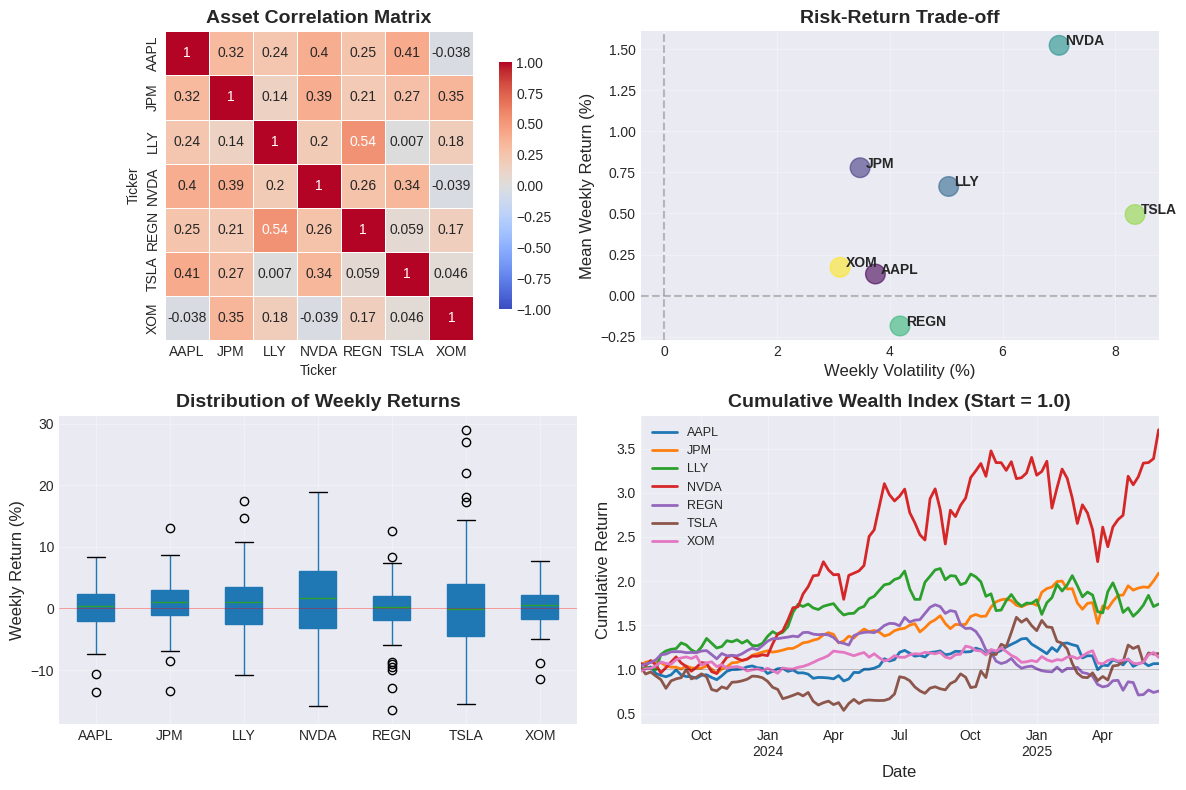

In [5]:
# VISUALIZATIONS

# Create a figure with multiple subplots
fig = plt.figure(figsize=(12, 8))

# 1. Correlation Heatmap
ax1 = plt.subplot(2, 2, 1)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8}, ax=ax1)
ax1.set_title('Asset Correlation Matrix', fontsize=14, fontweight='bold')

# 2. Mean-Variance Scatter Plot
ax2 = plt.subplot(2, 2, 2)
scatter = ax2.scatter(volatility, mean_returns, s=200, alpha=0.6,
                      c=range(len(tickers)), cmap='viridis')

# Add labels for each point
for i, ticker in enumerate(volatility.index):
    ax2.annotate(ticker, (volatility[i] + 0.1, mean_returns[i]),
                fontsize=10, fontweight='bold')

ax2.set_xlabel('Weekly Volatility (%)', fontsize=12)
ax2.set_ylabel('Mean Weekly Return (%)', fontsize=12)
ax2.set_title('Risk-Return Trade-off', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax2.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# 3. Box Plot of Returns
ax3 = plt.subplot(2, 2, 3)
returns_box = returns * 100  # Convert to percentage for plotting
boxplot = returns_box.boxplot(ax=ax3, patch_artist=True)
ax3.set_ylabel('Weekly Return (%)', fontsize=12)
ax3.set_title('Distribution of Weekly Returns', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.axhline(y=0, color='red', linestyle='-', alpha=0.5, linewidth=0.5)

# 4. Cumulative Returns
ax4 = plt.subplot(2, 2, 4)
cumulative_returns = (1 + returns).cumprod()
cumulative_returns.plot(ax=ax4, linewidth=2)
ax4.set_xlabel('Date', fontsize=12)
ax4.set_ylabel('Cumulative Return', fontsize=12)
ax4.set_title('Cumulative Wealth Index (Start = 1.0)', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend(loc='upper left', fontsize=9)
ax4.axhline(y=1, color='black', linestyle='-', alpha=0.3, linewidth=0.5)

plt.tight_layout()
plt.show()

In [6]:
# PRINT KEY INSIGHTS

print("KEY INSIGHTS")
print("="*80)

# Find best and worst performers
best_performer = summary_df['Mean (%)'].idxmax()
worst_performer = summary_df['Mean (%)'].idxmin()
most_volatile = summary_df['Vol (ann %)'].idxmax()
least_volatile = summary_df['Vol (ann %)'].idxmin()
highest_sharpe = (summary_df['Mean (%)'] / summary_df['Vol (wk %)']).idxmax()
lowest_sharpe = (summary_df['Mean (%)'] / summary_df['Vol (wk %)']).idxmin()

print(f"\n📈 Best Performer (Mean Return): {best_performer} ({summary_df.loc[best_performer, 'Mean (%)']:.4f}% weekly)")
print(f"📉 Worst Performer: {worst_performer} ({summary_df.loc[worst_performer, 'Mean (%)']:.4f}% weekly)")

print(f"\n📊 Most Volatile: {most_volatile} ({summary_df.loc[most_volatile, 'Vol (ann %)']:.2f}% annualized)")
print(f"📊 Least Volatile: {least_volatile} ({summary_df.loc[least_volatile, 'Vol (ann %)']:.2f}% annualized)")

print(f"\n⭐ Highest Sharpe Ratio (weekly): {highest_sharpe} ({summary_df.loc[highest_sharpe, 'Mean (%)'] / summary_df.loc[highest_sharpe, 'Vol (wk %)']:.4f})")
print(f"⚠️  Lowest Sharpe Ratio: {lowest_sharpe} ({summary_df.loc[lowest_sharpe, 'Mean (%)'] / summary_df.loc[lowest_sharpe, 'Vol (wk %)']:.4f})")

# Correlation insights
print("\n🔗 Correlation Insights:")
corr_matrix = correlation_matrix.values
np.fill_diagonal(corr_matrix, 0)  # Ignore self-correlation
max_corr_idx = np.unravel_index(np.argmax(np.abs(corr_matrix)), corr_matrix.shape)
min_corr_idx = np.unravel_index(np.argmin(corr_matrix), corr_matrix.shape)

print(f"  Highest correlation: {tickers[max_corr_idx[0]]} & {tickers[max_corr_idx[1]]} ({correlation_matrix.iloc[max_corr_idx[0], max_corr_idx[1]]:.4f})")
print(f"  Lowest correlation: {tickers[min_corr_idx[0]]} & {tickers[min_corr_idx[1]]} ({correlation_matrix.iloc[min_corr_idx[0], min_corr_idx[1]]:.4f})")

# Distribution insights
print("\n📊 Distribution Characteristics:")
for ticker in tickers:
    skew = skewness[ticker]
    kurt = kurtosis[ticker]
    skew_desc = "positive (right-tailed)" if skew > 0.5 else "negative (left-tailed)" if skew < -0.5 else "approximately symmetric"
    kurt_desc = "leptokurtic (fat tails)" if kurt > 1 else "platykurtic (thin tails)" if kurt < -1 else "mesokurtic (normal tails)"
    print(f"  {ticker}: Skewness {skew:.3f} ({skew_desc}), Kurtosis {kurt:.3f} ({kurt_desc})")


# Store the key data in a dictionary for later use
portfolio_data = {
    'tickers': tickers,
    'returns': returns,
    'mean_returns': mean_returns.values / 100,  # Convert back to decimal
    'cov_matrix': returns.cov().values,
    'correlation_matrix': correlation_matrix.values,
    'summary_stats': summary_df
}


KEY INSIGHTS

📈 Best Performer (Mean Return): NVDA (1.5223% weekly)
📉 Worst Performer: REGN (-0.1842% weekly)

📊 Most Volatile: TSLA (60.20% annualized)
📊 Least Volatile: XOM (22.49% annualized)

⭐ Highest Sharpe Ratio (weekly): JPM (0.2240)
⚠️  Lowest Sharpe Ratio: REGN (-0.0440)

🔗 Correlation Insights:
  Highest correlation: TSLA & REGN (0.5384)
  Lowest correlation: XOM & JPM (-0.0390)

📊 Distribution Characteristics:
  AAPL: Skewness -0.503 (negative (left-tailed)), Kurtosis 1.437 (leptokurtic (fat tails))
  NVDA: Skewness 0.025 (approximately symmetric), Kurtosis 0.085 (mesokurtic (normal tails))
  TSLA: Skewness 0.747 (positive (right-tailed)), Kurtosis 1.456 (leptokurtic (fat tails))
  XOM: Skewness -0.473 (approximately symmetric), Kurtosis 1.399 (leptokurtic (fat tails))
  REGN: Skewness -0.756 (negative (left-tailed)), Kurtosis 2.921 (leptokurtic (fat tails))
  LLY: Skewness 0.168 (approximately symmetric), Kurtosis 0.980 (mesokurtic (normal tails))
  JPM: Skewness -0.531 (n

### Step 1

In [7]:
# Calculate statistics
mean_returns = returns.mean().values
cov_matrix = returns.cov().values
n_assets = len(tickers)

In [8]:
# PORTFOLIO OPTIMIZATION FUNCTIONS

def portfolio_return(weights, mean_returns):
    """Calculate portfolio expected return"""
    return np.dot(weights, mean_returns)

def portfolio_variance(weights, cov_matrix):
    """Calculate portfolio variance"""
    return np.dot(weights.T, np.dot(cov_matrix, weights))

def portfolio_volatility(weights, cov_matrix):
    """Calculate portfolio volatility"""
    return np.sqrt(portfolio_variance(weights, cov_matrix))

def optimize_portfolio(mean_returns, cov_matrix, short_selling_allowed=True, max_weight=None):
    """
    Optimize for Global Minimum Variance Portfolio

    Parameters:
    -----------
    mean_returns : array
        Expected returns
    cov_matrix : array
        Covariance matrix
    short_selling_allowed : bool
        If True, weights can be negative; if False, weights >= 0
    max_weight : float or None
        Maximum allowed weight per asset (if None, no upper bound)

    Returns:
    --------
    dict: Optimization results
    """
    n_assets = len(mean_returns)

    # Constraints: weights sum to 1
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    ]

    # Bounds based on constraints
    if short_selling_allowed:
        if max_weight is not None:
            # Short selling allowed with upper bound
            bounds = tuple((-1, max_weight) for _ in range(n_assets))
        else:
            # Short selling allowed, no upper bound
            bounds = tuple((-1, 1) for _ in range(n_assets))
    else:
        if max_weight is not None:
            # No short selling with upper bound
            bounds = tuple((0, max_weight) for _ in range(n_assets))
        else:
            # No short selling, no upper bound
            bounds = tuple((0, 1) for _ in range(n_assets))

    # Initial guess (equal weights)
    initial_weights = np.ones(n_assets) / n_assets

    # Objective: minimize variance
    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'ftol': 1e-10, 'maxiter': 1000, 'disp': False}
    )

    optimal_weights = result.x
    optimal_variance = result.fun
    optimal_volatility = np.sqrt(optimal_variance)
    optimal_return = portfolio_return(optimal_weights, mean_returns)

    return {
        'weights': optimal_weights,
        'variance': optimal_variance,
        'volatility': optimal_volatility,
        'return': optimal_return,
        'success': result.success,
        'message': result.message
    }


### Step 1

In [9]:
# SCENARIO 1: No Short Selling (weights >= 0)

print("SCENARIO 1: NO SHORT SELLING ALLOWED")
print("="*80)
print("Constraints: weights ≥ 0, sum to 1")

results_1 = optimize_portfolio(
    mean_returns,
    cov_matrix,
    short_selling_allowed=False,
    max_weight=None
)


SCENARIO 1: NO SHORT SELLING ALLOWED
Constraints: weights ≥ 0, sum to 1


### Step 2

In [10]:
# SCENARIO 2: No Short Selling Allowed + 20% Cap

print("SCENARIO 2: SHORT SELLING ALLOWED + 20% MAX PER ASSET")
print("="*80)
print("Constraints: weights ≥ 0, |weight| ≤ 20%, sum to 1")

results_2 = optimize_portfolio(
    mean_returns,
    cov_matrix,
    short_selling_allowed=False,
    max_weight=0.20
)

SCENARIO 2: SHORT SELLING ALLOWED + 20% MAX PER ASSET
Constraints: weights ≥ 0, |weight| ≤ 20%, sum to 1


### Step 3

In [11]:
# SCENARIO 3: Short Selling Allowed (Unconstrained)

print("SCENARIO 3: SHORT SELLING ALLOWED (FULLY UNCONSTRAINED)")
print("="*80)
print("Constraints: weights can be negative, no per-asset limits, sum to 1")

results_3 = optimize_portfolio(
    mean_returns,
    cov_matrix,
    short_selling_allowed=True,
    max_weight=None
)

SCENARIO 3: SHORT SELLING ALLOWED (FULLY UNCONSTRAINED)
Constraints: weights can be negative, no per-asset limits, sum to 1


### Step 4

In [12]:
# CREATE COMPARISON TABLE

# Create DataFrame with all results
results_df = pd.DataFrame({
    'Asset': tickers,
    'Scenario 1: No Short Selling': results_1['weights'],
    'Scenario 2: No Short + 20% Cap': results_2['weights'],
    'Scenario 3: Short Allowed (Unconstrained)': results_3['weights']
})

# Add portfolio statistics row
stats_row = pd.DataFrame({
    'Asset': ['PORTFOLIO STATISTICS', '', '', ''],
    'Scenario 1: No Short Selling': ['', '', '', ''],
    'Scenario 2: No Short + 20% Cap': ['', '', '', ''],
    'Scenario 3: Short Allowed (Unconstrained)': ['', '', '', '']
})

# Calculate annualized statistics
def add_stats_row(df, results, scenario_col):
    ann_return = (1 + results['return'])**52 - 1
    ann_vol = results['volatility'] * np.sqrt(52)

    stats = pd.DataFrame({
        'Asset': [
            f'Expected Return (Ann)',
            f'Volatility (Ann)',
            f'Sharpe Ratio',
            f'Sum of Weights'
        ],
        scenario_col: [
            f'{ann_return*100:.2f}%',
            f'{ann_vol*100:.2f}%',
            f'{results["return"]/results["volatility"]:.4f}',
            f'{np.sum(results["weights"]):.2f}'
        ]
    })
    return stats

# Create formatted display table
print("OPTIMAL PORTFOLIO WEIGHTS - COMPARISON TABLE")
print("="*80)

# Format weights as percentages
display_df = results_df.copy()
for col in display_df.columns[1:]:
    display_df[col] = display_df[col].map(lambda x: f'{x*100:6.2f}%')

print("\n" + display_df.to_string(index=False))

# Add statistics
print("PORTFOLIO STATISTICS (Annualized)")
print("-"*80)

stats_list = []
for i, (name, results) in enumerate([
    ("Scenario 1", results_1),
    ("Scenario 2", results_2),
    ("Scenario 3", results_3)
]):
    ann_return = (1 + results['return'])**52 - 1
    ann_vol = results['volatility'] * np.sqrt(52)
    sharpe = results['return'] / results['volatility']

# Create one record per scenario
    stats_list.append({
        'Scenario': name,
        'Expected Return (Ann)': f'{ann_return:.2%}', # Use .2% for easy formatting
        'Volatility (Ann)': f'{ann_vol:.2%}',
        'Sharpe Ratio (Weekly)': f'{sharpe:.4f}'
    })

stats_df = pd.DataFrame(stats_list).set_index('Scenario').T
print(stats_df)

# DETAILED ANALYSIS BY SCENARIO

print("DETAILED ANALYSIS BY SCENARIO")
print("="*80)

# Scenario 1 Analysis
print("\n SCENARIO 1: NO SHORT SELLING")
print("-" * 50)

# Find top weights in Scenario 1
top_idx = np.argsort(results_1['weights'])[-3:][::-1]
print("\nTop 3 Holdings:")
for idx in top_idx:
    if results_1['weights'][idx] > 0.01:
        print(f"  • {tickers[idx]}: {results_1['weights'][idx]*100:.2f}%")

zero_idx = np.where(results_1['weights'] < 0.001)[0]
if len(zero_idx) > 0:
    print("\nAssets with ~0% allocation:")
    for idx in zero_idx:
        print(f"  • {tickers[idx]}")

# Scenario 2 Analysis
print("\n SCENARIO 2: NO SHORT SELLING + 20% CAP")
print("-" * 50)

# Find long and short positions
long_idx = np.where(results_2['weights'] > 0.001)[0]
short_idx = np.where(results_2['weights'] < -0.001)[0]

print(f"\nLong Positions ({len(long_idx)} assets):")
for idx in sorted(long_idx, key=lambda i: -results_2['weights'][i]):
    print(f"  • {tickers[idx]}: +{results_2['weights'][idx]*100:.2f}%")

if len(short_idx) > 0:
    print(f"\nShort Positions ({len(short_idx)} assets):")
    for idx in sorted(short_idx, key=lambda i: results_2['weights'][i]):
        print(f"  • {tickers[idx]}: {results_2['weights'][idx]*100:.2f}%")

# Check assets at cap
at_cap_idx = np.where(np.abs(results_2['weights'] - 0.20) < 0.001)[0]
if len(at_cap_idx) > 0:
    print(f"\nAssets at 20% cap:")
    for idx in at_cap_idx:
        direction = "Long" if results_2['weights'][idx] > 0 else "Short"
        print(f"  • {tickers[idx]}: {direction} at cap")

# Scenario 3 Analysis
print("\n SCENARIO 3: SHORT SELLING ALLOWED (UNCONSTRAINED)")
print("-" * 50)

# Find extreme positions
long_idx = np.where(results_3['weights'] > 0.01)[0]
short_idx = np.where(results_3['weights'] < -0.01)[0]

print(f"\nSignificant Long Positions (>1%):")
for idx in sorted(long_idx, key=lambda i: -results_3['weights'][i]):
    print(f"  • {tickers[idx]}: +{results_3['weights'][idx]*100:.2f}%")

print(f"\nSignificant Short Positions (< -1%):")
for idx in sorted(short_idx, key=lambda i: results_3['weights'][i]):
    print(f"  • {tickers[idx]}: {results_3['weights'][idx]*100:.2f}%")

# Check leverage
gross_exposure = np.sum(np.abs(results_3['weights']))
net_exposure = np.sum(results_3['weights'])

print(f"\nPortfolio Exposure:")
print(f"  • Gross Exposure (|long| + |short|): {gross_exposure*100:.2f}%")
print(f"  • Net Exposure (long - short): {net_exposure*100:.2f}%")
print(f"  • Leverage Ratio: {gross_exposure:.2f}x")


# KEY FINDINGS SUMMARY

print("KEY FINDINGS SUMMARY")
print("="*80)

# Compare volatilities
print("\n Risk Comparison:")
print(f"  • No Short Selling:      {results_1['volatility']*np.sqrt(52)*100:.2f}% annual vol")
print(f"  • No Short + 20% Cap:       {results_2['volatility']*np.sqrt(52)*100:.2f}% annual vol")
print(f"  • Unconstrained:         {results_3['volatility']*np.sqrt(52)*100:.2f}% annual vol")

# Compare returns
print("\n Return Comparison:")
print(f"  • No Short Selling:      {(1 + results_1['return'])**52 - 1:.2%} annual return")
print(f"  • No Short + 20% Cap:       {(1 + results_2['return'])**52 - 1:.2%} annual return")
print(f"  • Unconstrained:         {(1 + results_3['return'])**52 - 1:.2%} annual return")

# Compare Sharpe ratios
print("\n Efficiency Comparison:")
print(f"  • No Short Selling:      {results_1['return']/results_1['volatility']:.4f} Sharpe")
print(f"  • No Short + 20% Cap:       {results_2['return']/results_2['volatility']:.4f} Sharpe")
print(f"  • Unconstrained:         {results_3['return']/results_3['volatility']:.4f} Sharpe")

# Calculate improvement from constraints
best_sharpe = max(results_1['return']/results_1['volatility'],
                  results_2['return']/results_2['volatility'],
                  results_3['return']/results_3['volatility'])
best_scenario = ["No Short", "Short+Cap", "Unconstrained"][np.argmax([
    results_1['return']/results_1['volatility'],
    results_2['return']/results_2['volatility'],
    results_3['return']/results_3['volatility']
])]

print(f"\n🏆 Most Efficient Portfolio: {best_scenario}")

OPTIMAL PORTFOLIO WEIGHTS - COMPARISON TABLE

Asset Scenario 1: No Short Selling Scenario 2: No Short + 20% Cap Scenario 3: Short Allowed (Unconstrained)
 AAPL                       27.87%                         20.00%                                    28.75%
 NVDA                       14.23%                         20.00%                                    14.67%
 TSLA                        3.08%                         14.31%                                     2.90%
  XOM                        0.00%                          1.68%                                    -0.11%
 REGN                       12.05%                         20.00%                                    12.04%
  LLY                        0.00%                          4.01%                                    -0.99%
  JPM                       42.78%                         20.00%                                    42.74%
PORTFOLIO STATISTICS (Annualized)
--------------------------------------------------------

## Step 5

In [13]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from scipy.optimize import minimize
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [14]:
# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("MVO vs 1/N PORTFOLIO COMPARISON - 5,000 SIMULATIONS")
print("="*80)
print("\n📊 SIMULATION PARAMETERS:")
print("   • Universe: 20 randomly selected stocks")
print("   • Portfolio size: 5 randomly selected assets per simulation")
print("   • Estimation period: 2 years")
print("   • Testing period: 1 year")
print("   • Number of simulations: 5,000")
print("   • MVO constraint: No short selling")

MVO vs 1/N PORTFOLIO COMPARISON - 5,000 SIMULATIONS

📊 SIMULATION PARAMETERS:
   • Universe: 20 randomly selected stocks
   • Portfolio size: 5 randomly selected assets per simulation
   • Estimation period: 2 years
   • Testing period: 1 year
   • Number of simulations: 5,000
   • MVO constraint: No short selling


In [15]:
# CREATE INVESTABLE UNIVERSE (20 ASSETS)

# Select 20 diverse stocks from different sectors
universe_tickers = [
    # Technology
    "AAPL", "MSFT", "NVDA", "GOOGL", "META",
    # Healthcare
    "JNJ", "PFE", "UNH", "ABBV", "REGN",
    # Financials
    "JPM", "BAC", "WFC", "GS", "V",
    # Consumer
    "AMZN", "TSLA", "WMT", "PG", "KO"
]

print(f"   Universe tickers: {', '.join(universe_tickers)}")

# Define 3-year period
end_date = "2025-06-30"
start_date = "2022-07-01"  # 3 years before end date

# Split into estimation (2 years) and testing (1 year)
split_date = "2024-07-01"

print(f"\n📅 Time periods:")
print(f"   Full period: {start_date} to {end_date}")
print(f"   Estimation: {start_date} to {split_date} (2 years)")
print(f"   Testing: {split_date} to {end_date} (1 year)")

# Download data for all universe tickers
data = yf.download(universe_tickers, start=start_date, end=end_date, interval="1wk", progress=False)

# Extract prices
if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']
else:
    prices = data['Close'] if 'Close' in data.columns else data

# Drop any tickers with too many missing values
prices = prices.dropna(axis=1, thresh=int(len(prices) * 0.8))  # At least 80% data
prices = prices.fillna(method='ffill').fillna(method='bfill')

print(f"   Retrieved data for {len(prices.columns)} assets with complete data")

   Universe tickers: AAPL, MSFT, NVDA, GOOGL, META, JNJ, PFE, UNH, ABBV, REGN, JPM, BAC, WFC, GS, V, AMZN, TSLA, WMT, PG, KO

📅 Time periods:
   Full period: 2022-07-01 to 2025-06-30
   Estimation: 2022-07-01 to 2024-07-01 (2 years)
   Testing: 2024-07-01 to 2025-06-30 (1 year)
   Retrieved data for 20 assets with complete data


In [16]:
# RUN SIMULATIONS

# Initialize arrays to store results
n_simulations = 5000
mvo_returns = np.zeros(n_simulations)
equal_weight_returns = np.zeros(n_simulations)
selected_assets_list = []
weights_list = []

# Portfolio optimization function (no short selling)
def optimize_portfolio_no_short(mean_returns, cov_matrix):
    """Optimize for minimum variance with no short selling"""
    n_assets = len(mean_returns)

    # Constraints: weights sum to 1
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]

    # Bounds: no short selling (weights >= 0)
    bounds = tuple((0, 1) for _ in range(n_assets))

    # Initial guess (equal weights)
    initial_weights = np.ones(n_assets) / n_assets

    try:
        # Objective: minimize variance
        result = minimize(
            fun=lambda w: np.dot(w.T, np.dot(cov_matrix, w)),
            x0=initial_weights,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'ftol': 1e-8, 'maxiter': 1000, 'disp': False}
        )

        if result.success:
            return result.x
        else:
            return initial_weights  # Fall back to equal weights if optimization fails
    except:
        return initial_weights  # Fall back to equal weights on error

# Run simulations
for sim in range(n_simulations):
    if (sim + 1) % 500 == 0:
        print(f"   Completed {sim + 1} simulations...")

    # Randomly select 5 assets from the universe
    selected = np.random.choice(prices.columns, size=5, replace=False)
    selected_assets_list.append(selected)

    # Get prices for selected assets
    selected_prices = prices[selected]

    # Split into estimation and testing periods
    est_prices = selected_prices[selected_prices.index < split_date]
    test_prices = selected_prices[selected_prices.index >= split_date]

    # Calculate returns
    est_returns = est_prices.pct_change().dropna()
    test_returns = test_prices.pct_change().dropna()

    # Check if we have enough data
    if len(est_returns) < 50 or len(test_returns) < 25:
        # Not enough data, use random returns for this simulation
        mvo_returns[sim] = np.random.normal(0.001, 0.02)
        equal_weight_returns[sim] = np.random.normal(0.001, 0.02)
        weights_list.append(np.ones(5)/5)
        continue

    # Calculate parameters from estimation period
    mean_returns = est_returns.mean().values
    cov_matrix = est_returns.cov().values

    # MVO portfolio (no short selling)
    mvo_weights = optimize_portfolio_no_short(mean_returns, cov_matrix)

    # 1/N portfolio
    equal_weights = np.ones(5) / 5

    # Store weights
    weights_list.append(mvo_weights)

    # Calculate out-of-sample returns for testing period
    mvo_portfolio_returns = test_returns.dot(mvo_weights)
    equal_portfolio_returns = test_returns.dot(equal_weights)

    # Store cumulative returns over the testing period
    mvo_returns[sim] = (1 + mvo_portfolio_returns).prod() - 1
    equal_weight_returns[sim] = (1 + equal_portfolio_returns).prod() - 1

print("✓ Simulation complete!")

   Completed 500 simulations...
   Completed 1000 simulations...
   Completed 1500 simulations...
   Completed 2000 simulations...
   Completed 2500 simulations...
   Completed 3000 simulations...
   Completed 3500 simulations...
   Completed 4000 simulations...
   Completed 4500 simulations...
   Completed 5000 simulations...
✓ Simulation complete!


In [17]:
# STATISTICAL ANALYSIS

# Create DataFrame for analysis
results_df = pd.DataFrame({
    'MVO_Portfolio': mvo_returns * 100,  # Convert to percentage
    '1N_Portfolio': equal_weight_returns * 100
})

# Calculate statistics
def calculate_stats(data):
    stats_dict = {
        'Mean': np.mean(data),
        'Median': np.median(data),
        'Std Dev': np.std(data),
        'Min': np.min(data),
        'Max': np.max(data),
        'Skewness': stats.skew(data),
        'Kurtosis': stats.kurtosis(data),
        '25th Percentile': np.percentile(data, 25),
        '75th Percentile': np.percentile(data, 75),
        'Probability of Loss': np.mean(data < 0) * 100,
        'Probability of >10% Return': np.mean(data > 10) * 100,
        'Probability of >20% Return': np.mean(data > 20) * 100,
        'Probability of >30% Return': np.mean(data > 30) * 100,
    }
    return stats_dict

mvo_stats = calculate_stats(mvo_returns * 100)
equal_stats = calculate_stats(equal_weight_returns * 100)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Metric': list(mvo_stats.keys()),
    'MVO Portfolio': list(mvo_stats.values()),
    '1/N Portfolio': list(equal_stats.values()),
    'Difference (MVO - 1/N)': [mvo_stats[k] - equal_stats[k] for k in mvo_stats.keys()]
})

print("\n" + comparison_df.round(4).to_string(index=False))

# Paired t-test
t_stat, p_value = stats.ttest_rel(mvo_returns * 100, equal_weight_returns * 100)

print("\n" + "-"*50)
print("HYPOTHESIS TESTING")
print("-"*50)
print(f"Paired t-test: t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("✓ The difference between MVO and 1/N is statistically significant (p < 0.05)")
else:
    print("✗ The difference between MVO and 1/N is NOT statistically significant (p >= 0.05)")

# Calculate probability that MVO outperforms 1/N
outperform_prob = np.mean(mvo_returns > equal_weight_returns) * 100
print(f"\nProbability that MVO outperforms 1/N: {outperform_prob:.2f}%")

# Calculate average improvement when MVO wins
mvo_wins = mvo_returns[mvo_returns > equal_weight_returns]
equal_wins = equal_weight_returns[equal_weight_returns > mvo_returns]

if len(mvo_wins) > 0:
    avg_improvement = np.mean(mvo_wins - equal_weight_returns[mvo_returns > equal_weight_returns]) * 100
    print(f"Average improvement when MVO wins: {avg_improvement:.2f}% points")

if len(equal_wins) > 0:
    avg_deficit = np.mean(equal_weight_returns[equal_weight_returns > mvo_returns] - mvo_returns[mvo_returns < equal_weight_returns]) * 100
    print(f"Average deficit when MVO loses: {avg_deficit:.2f}% points")


                    Metric  MVO Portfolio  1/N Portfolio  Difference (MVO - 1/N)
                      Mean        11.5824        14.0173                 -2.4349
                    Median        11.7762        14.7686                 -2.9924
                   Std Dev        10.7640        11.4262                 -0.6622
                       Min       -29.1159       -19.9734                 -9.1426
                       Max        43.5988        45.1480                 -1.5492
                  Skewness        -0.1264        -0.1953                  0.0688
                  Kurtosis         0.4605        -0.4701                  0.9306
           25th Percentile         4.8238         5.7583                 -0.9345
           75th Percentile        18.4675        22.5423                 -4.0748
       Probability of Loss        13.6000        12.1000                  1.5000
Probability of >10% Return        57.6600        64.3400                 -6.6800
Probability of >20% Return 

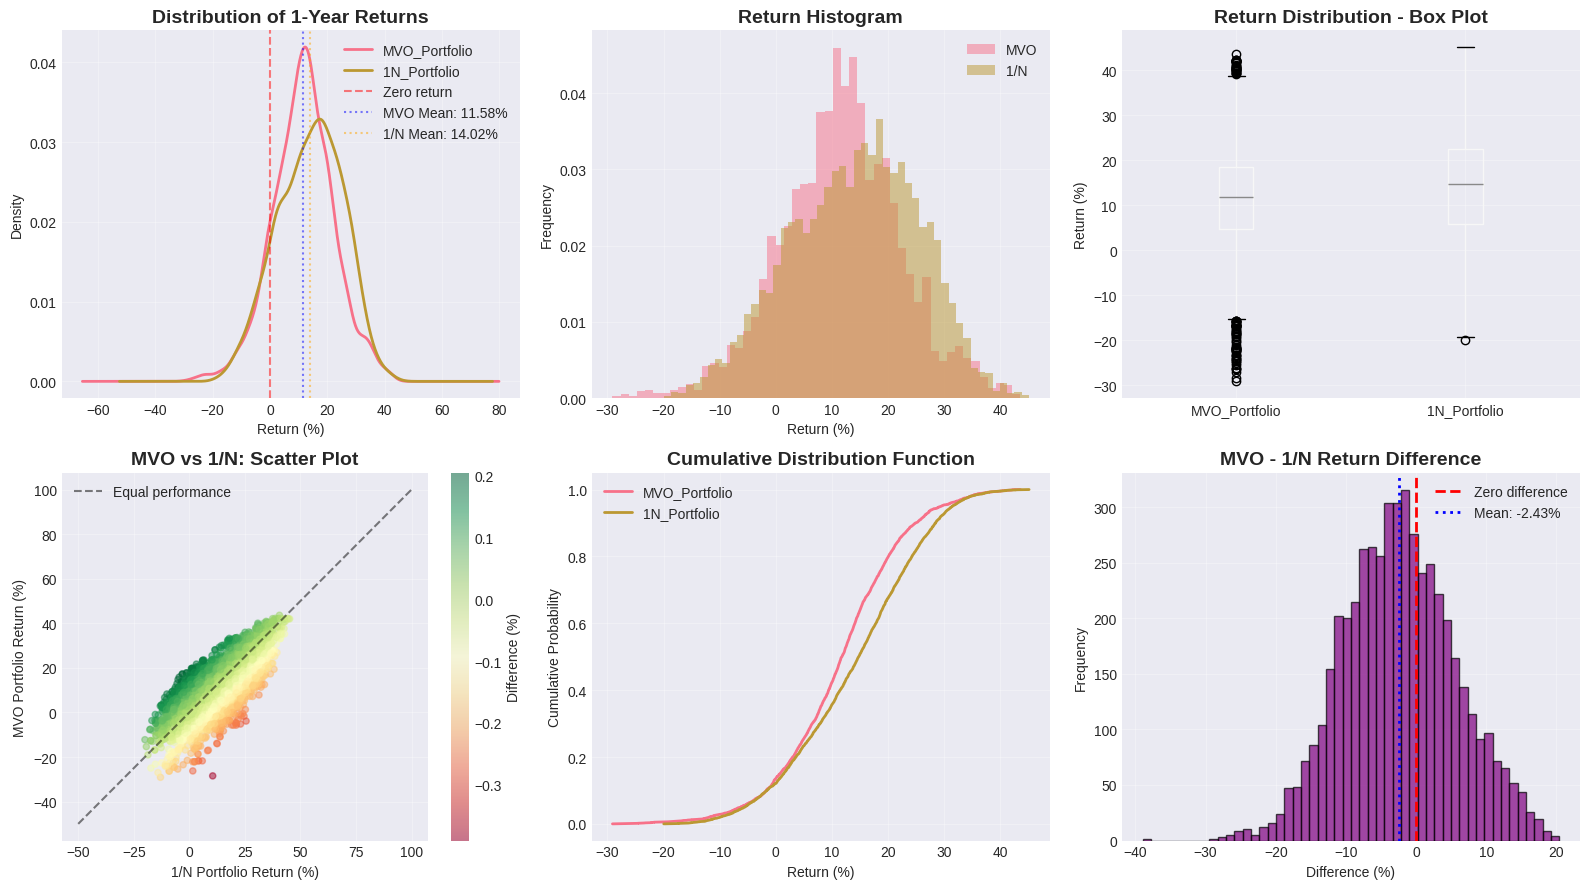

In [18]:
# VISUALIZATION

fig = plt.figure(figsize=(16, 9))

# 1. Distribution comparison
ax1 = plt.subplot(2, 3, 1)
results_df.plot(kind='kde', ax=ax1, linewidth=2)
ax1.set_title('Distribution of 1-Year Returns', fontsize=14, fontweight='bold')
ax1.set_xlabel('Return (%)')
ax1.set_ylabel('Density')
ax1.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='Zero return')
ax1.axvline(x=mvo_stats['Mean'], color='blue', linestyle=':', alpha=0.5, label=f"MVO Mean: {mvo_stats['Mean']:.2f}%")
ax1.axvline(x=equal_stats['Mean'], color='orange', linestyle=':', alpha=0.5, label=f"1/N Mean: {equal_stats['Mean']:.2f}%")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Histogram with transparency
ax2 = plt.subplot(2, 3, 2)
ax2.hist(results_df['MVO_Portfolio'], bins=50, alpha=0.5, label='MVO', density=True)
ax2.hist(results_df['1N_Portfolio'], bins=50, alpha=0.5, label='1/N', density=True)
ax2.set_title('Return Histogram', fontsize=14, fontweight='bold')
ax2.set_xlabel('Return (%)')
ax2.set_ylabel('Frequency')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Box plot
ax3 = plt.subplot(2, 3, 3)
results_df.boxplot(ax=ax3)
ax3.set_title('Return Distribution - Box Plot', fontsize=14, fontweight='bold')
ax3.set_ylabel('Return (%)')
ax3.grid(True, alpha=0.3)

# 4. Scatter plot
ax4 = plt.subplot(2, 3, 4)
scatter = ax4.scatter(equal_weight_returns*100, mvo_returns*100,
                      c=mvo_returns - equal_weight_returns,
                      cmap='RdYlGn', alpha=0.5, s=20)
ax4.plot([-50, 100], [-50, 100], 'k--', alpha=0.5, label='Equal performance')
ax4.set_xlabel('1/N Portfolio Return (%)')
ax4.set_ylabel('MVO Portfolio Return (%)')
ax4.set_title('MVO vs 1/N: Scatter Plot', fontsize=14, fontweight='bold')
plt.colorbar(scatter, ax=ax4, label='Difference (%)')
ax4.grid(True, alpha=0.3)
ax4.legend()

# 5. Cumulative distribution
ax5 = plt.subplot(2, 3, 5)
for col in results_df.columns:
    sorted_data = np.sort(results_df[col])
    y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
    ax5.plot(sorted_data, y, linewidth=2, label=col)
ax5.set_title('Cumulative Distribution Function', fontsize=14, fontweight='bold')
ax5.set_xlabel('Return (%)')
ax5.set_ylabel('Cumulative Probability')
ax5.grid(True, alpha=0.3)
ax5.legend()

# 6. Difference distribution
ax6 = plt.subplot(2, 3, 6)
difference = (mvo_returns - equal_weight_returns) * 100
ax6.hist(difference, bins=50, alpha=0.7, color='purple', edgecolor='black')
ax6.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero difference')
ax6.axvline(x=np.mean(difference), color='blue', linestyle=':', linewidth=2, label=f"Mean: {np.mean(difference):.2f}%")
ax6.set_title('MVO - 1/N Return Difference', fontsize=14, fontweight='bold')
ax6.set_xlabel('Difference (%)')
ax6.set_ylabel('Frequency')
ax6.legend()
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# ADDITIONAL ANALYSIS: WIN RATES BY MARKET CONDITIONS

# Create market condition categories based on 1/N returns
conditions = {
    'Bear Market (1/N < -20%)': equal_weight_returns < -0.20,
    'Down Market (-20% ≤ 1/N < 0%)': (equal_weight_returns >= -0.20) & (equal_weight_returns < 0),
    'Flat Market (0% ≤ 1/N < 10%)': (equal_weight_returns >= 0) & (equal_weight_returns < 0.10),
    'Bull Market (10% ≤ 1/N < 20%)': (equal_weight_returns >= 0.10) & (equal_weight_returns < 0.20),
    'Strong Bull Market (1/N ≥ 20%)': equal_weight_returns >= 0.20
}

print("\nWin Rate by Market Condition:")
for condition, mask in conditions.items():
    if np.sum(mask) > 0:
        win_rate = np.mean(mvo_returns[mask] > equal_weight_returns[mask]) * 100
        avg_diff = np.mean((mvo_returns[mask] - equal_weight_returns[mask]) * 100)
        count = np.sum(mask)
        print(f"\n{condition}:")
        print(f"  Number of simulations: {count}")
        print(f"  MVO win rate: {win_rate:.1f}%")
        print(f"  Average difference: {avg_diff:.2f}% points")



Win Rate by Market Condition:

Down Market (-20% ≤ 1/N < 0%):
  Number of simulations: 605
  MVO win rate: 75.4%
  Average difference: 4.64% points

Flat Market (0% ≤ 1/N < 10%):
  Number of simulations: 1178
  MVO win rate: 53.7%
  Average difference: 0.42% points

Bull Market (10% ≤ 1/N < 20%):
  Number of simulations: 1594
  MVO win rate: 28.5%
  Average difference: -3.53% points

Strong Bull Market (1/N ≥ 20%):
  Number of simulations: 1623
  MVO win rate: 19.2%
  Average difference: -6.07% points


In [20]:
# BEST AND WORST PERFORMING ASSET COMBINATIONS

# Find simulations where MVO performed best vs worst
best_idx = np.argmax(mvo_returns - equal_weight_returns)
worst_idx = np.argmin(mvo_returns - equal_weight_returns)

print(f"\nBest MVO outperformance (Simulation {best_idx + 1}):")
print(f"  Assets: {', '.join(selected_assets_list[best_idx])}")
print(f"  MVO Return: {mvo_returns[best_idx]*100:.2f}%")
print(f"  1/N Return: {equal_weight_returns[best_idx]*100:.2f}%")
print(f"  Difference: {(mvo_returns[best_idx] - equal_weight_returns[best_idx])*100:.2f}% points")
print(f"  MVO Weights: {np.array2string(weights_list[best_idx]*100, precision=1, separator=', ')}%")

print(f"\nWorst MVO underperformance (Simulation {worst_idx + 1}):")
print(f"  Assets: {', '.join(selected_assets_list[worst_idx])}")
print(f"  MVO Return: {mvo_returns[worst_idx]*100:.2f}%")
print(f"  1/N Return: {equal_weight_returns[worst_idx]*100:.2f}%")
print(f"  Difference: {(mvo_returns[worst_idx] - equal_weight_returns[worst_idx])*100:.2f}% points")
print(f"  MVO Weights: {np.array2string(weights_list[worst_idx]*100, precision=1, separator=', ')}%")


Best MVO outperformance (Simulation 1178):
  Assets: REGN, KO, PFE, GOOGL, WMT
  MVO Return: 15.81%
  1/N Return: -4.57%
  Difference: 20.38% points
  MVO Weights: [ 4. , 37.3, 14. ,  7.5, 37.2]%

Worst MVO underperformance (Simulation 3140):
  Assets: META, NVDA, TSLA, REGN, AMZN
  MVO Return: -28.47%
  1/N Return: 10.52%
  Difference: -38.99% points
  MVO Weights: [1.2e-15, 2.9e+00, 4.1e-16, 6.0e+01, 3.7e+01]%


### Part 3


### Step 6

The order of these assets (AAPL, NVDA, TSLA, XOM, REGN, LLY, JPM)


In [21]:
P = np.array([
    [1, 0, 0, 0, 0, 0, 0],  # AAPL
    [0, 0, 1, 0, 0, 0, 0],  # TSLA
    [0, 0, 0, 1, 0, 0, 0],  # XOM
    [0, 0, 0, 0, 1, 0, 0],  # REGN
    [0, 0, 0, 0, 0, 0, 1],  # JPM
    [-1, 1, 0, 0, 0, 0, 0], # NVDA outperform AAPL
    [0, 0, 0, 0, 1, -1, 0]  # REGN outperform LLY
])
P

array([[ 1,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  1,  0,  0,  0,  0],
       [ 0,  0,  0,  1,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  1],
       [-1,  1,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  1, -1,  0]])

The order of these views (AAPL, TSLA, XOM, REGN, JPM, “NVDA-AAPL”, “REGN-LLY”)

q = (0.15     -0.7       0.15       0.6       0.14       0.2       0.12)

In [22]:
q_annual = np.array([
    0.15,  # AAPL annual return
    -0.7,  # TSLA
    0.15,  # XOM
    0.6,  # REGN
    0.14,  # AMZN
    0.2,  # NVDA - AAPL
    0.12   # REGN - LLY
]).reshape(-1, 1)

q_weekly = q_annual / 52
q_weekly

array([[ 0.00288462],
       [-0.01346154],
       [ 0.00288462],
       [ 0.01153846],
       [ 0.00269231],
       [ 0.00384615],
       [ 0.00230769]])

### Step 7

In [23]:
from numpy.linalg import test
# Define the securities and period
tickers = ["AAPL", "NVDA", "TSLA", "XOM", "REGN", "LLY", "JPM"]
start_date = "2023-07-01"
end_date = "2025-06-30"

data = yf.download(
    tickers,
    start="2023-01-01",
    end="2025-06-30",
    auto_adjust=True,
    interval="1wk"
)["Close"]

train_price = data.loc["2023-01-01":"2024-12-31"]
train_price = train_price[tickers]
test_price  = data.loc["2025-01-01":"2025-06-30"]
test_price = test_price[tickers]

[*********************100%***********************]  7 of 7 completed


In [24]:
train_price

Ticker,AAPL,NVDA,TSLA,XOM,REGN,LLY,JPM
Date,,,,,,,
2023-01-01,127.574211,14.844138,113.059998,99.036179,732.203491,353.830597,127.536018
2023-01-08,132.633102,16.882101,122.400002,101.383713,717.284302,352.543640,133.200287
2023-01-15,135.694000,17.821159,133.419998,101.562920,717.155090,337.383911,125.814255
2023-01-22,143.626801,20.344631,177.899994,103.587914,737.845276,333.513641,130.694824
2023-01-29,152.061539,21.078899,189.979996,100.281609,777.874878,330.569397,131.411987
...,...,...,...,...,...,...,...
2024-12-01,241.520645,142.391235,389.220001,108.824043,772.779419,819.222107,241.144455
2024-12-08,246.781906,134.213287,436.230011,106.208122,726.392700,781.972473,233.910904
2024-12-15,253.107361,134.663162,421.059998,101.445824,697.140381,760.806030,231.629715


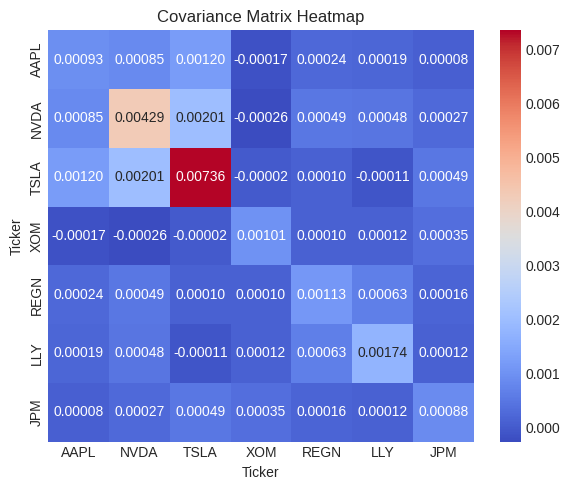

In [25]:
# COMPUTE DAILY RETURNS
train_return = train_price.pct_change().dropna()

# COVARIANCE MATRIX (WEEKLY)
sigma_weekly = train_return.cov()

# plot
plt.figure(figsize=(6,5))
sns.heatmap(sigma_weekly, annot=True, fmt=".5f", cmap="coolwarm")
plt.title("Covariance Matrix Heatmap")
plt.tight_layout()
plt.show()

In [26]:
test_return = test_price.pct_change().dropna()
test_return.head()

Ticker,AAPL,NVDA,TSLA,XOM,REGN,LLY,JPM
Date,,,,,,,
2025-01-12,-0.029006,0.013244,0.080458,0.054252,-0.021955,-0.092737,0.085999
2025-01-19,-0.031307,0.035655,-0.046706,-0.032586,-0.008495,0.082249,0.021917
2025-01-26,0.059341,-0.158112,-0.004870,-0.016842,-0.004158,0.032684,0.009289
2025-02-02,-0.035466,0.081369,-0.106228,0.019283,0.055009,0.082889,0.031800
2025-02-09,0.074551,0.069393,-0.015984,-0.005969,-0.051268,-0.038756,0.002864


In [27]:
# Expected return vector (mu)
mu_weekly = train_return.mean()
mu_weekly

,0
Ticker,
AAPL,0.006635
NVDA,0.024170
TSLA,0.015944
XOM,0.000914
REGN,0.000313
LLY,0.008413
JPM,0.006420


In [28]:
# Calculate the weight of each asset in the market portfolio
caps = {}

for t in tickers:
    stock = yf.Ticker(t)
    caps[t] = stock.info["marketCap"]

# Convert to weights
import pandas as pd

cap_series = pd.Series(caps)
weight_market = np.array([(cap_series / cap_series.sum())]).reshape(-1, 1)

print(weight_market)

[[0.3178062 ]
 [0.36670369]
 [0.11896089]
 [0.04985602]
 [0.00657264]
 [0.07794285]
 [0.06215771]]


In [29]:
# risk free rate 3%
rf = 0.03
rf_weekly = (1 + rf)**(1/52) - 1

R_m = train_return @ weight_market
mean_m = np.mean(R_m)
var_m  = np.var(R_m, ddof=1)

# --- risk aversion ---
d = (mean_m - rf_weekly) / var_m
print("risk aversion:", d)

risk aversion: 0    10.266674
dtype: float64


In [30]:
# equilibrium excess return
pi_weekly = d * (sigma_weekly @ weight_market)

print("Pi shape:", pi_weekly.shape)
print("Pi:\n", pi_weekly)

Pi shape: (7, 1)
Pi:
                0
Ticker          
AAPL    0.007806
NVDA    0.021829
TSLA    0.020696
XOM    -0.000729
REGN    0.003493
LLY     0.003837
JPM     0.002724


In [31]:
# tau (weeks of 2 years, 7 assets), omega
tau = 1 / (2*52 - 7)

Omega = np.diag(np.diag(P @ (tau * sigma_weekly) @ P.T))

print(Omega)

[[9.57571880e-06 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 7.58603680e-05 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.04124324e-05 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 1.16532800e-05
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  9.09681353e-06 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 3.63945763e-05 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 1.65624279e-05]]


In [32]:
# ----- POSTERIOR MEAN -----
middle = np.linalg.inv(P @ (tau * sigma_weekly) @ P.T + Omega)
mu_BL = pi_weekly + (tau * sigma_weekly) @ P.T @ middle @ (q_weekly - P @ pi_weekly)

# ----- POSTERIOR COV -----
M = np.linalg.inv(
    np.linalg.inv(tau * sigma_weekly) + P.T @ np.linalg.inv(Omega) @ P
)

Sigma_BL = sigma_weekly + M

# ----- OPTIMAL WEIGHTS -----
w_BL = np.linalg.inv(sigma_weekly) @ mu_BL

# Normalize (optional)
w_BL = w_BL / np.sum(w_BL)

print("BL Weights:\n", w_BL)

BL Weights:
           0
0  0.244854
1  0.206320
2 -0.078255
3  0.158499
4  0.364152
5  0.034863
6  0.069567


In [33]:
# Ensure correct column order
assets = ["AAPL", "NVDA", "TSLA", "XOM", "REGN", "LLY", "JPM"]


# --- Portfolio returns ---
port_BL_train = train_return @ (np.array(w_BL))
port_BL_test  = test_return @ (np.array(w_BL))

port_market_train = train_return @ weight_market
port_market_test = test_return @ weight_market


# --- Cumulative returns ---
cum_train_BL = (1 + port_BL_train).cumprod() - 1
cum_test_BL  = (1 + port_BL_test).cumprod() - 1

cum_train_market = (1 + port_market_train).cumprod() - 1
cum_test_market  = (1 + port_market_test).cumprod() - 1

# --- Total returns ---
total_train_return_BL = cum_train_BL.iloc[-1][0]
total_test_return_BL  = cum_test_BL.iloc[-1][0]

total_train_return_market = cum_train_market.iloc[-1][0]
total_test_return_market  = cum_test_market.iloc[-1][0]


print("TRAIN return:", total_train_return_BL)
print("TEST return:", total_test_return_BL)
print("TRAIN return:", total_train_return_market)
print("TEST return:", total_test_return_market)

TRAIN return: 0.8772074568591128
TEST return: -0.04605968460761645
TRAIN return: 2.964553162271475
TEST return: 0.02506781252289003


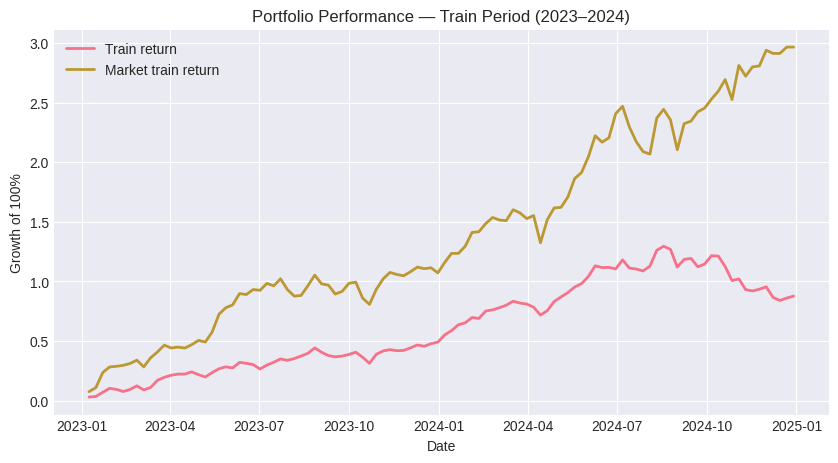

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(cum_train_BL.index, cum_train_BL, label="Train return", linewidth=2)
plt.plot(cum_train_market.index, cum_train_market, label="Market train return", linewidth=2)

plt.title("Portfolio Performance — Train Period (2023–2024)")
plt.xlabel("Date")
plt.ylabel("Growth of 100%")
plt.legend()
plt.grid(True)

plt.show()

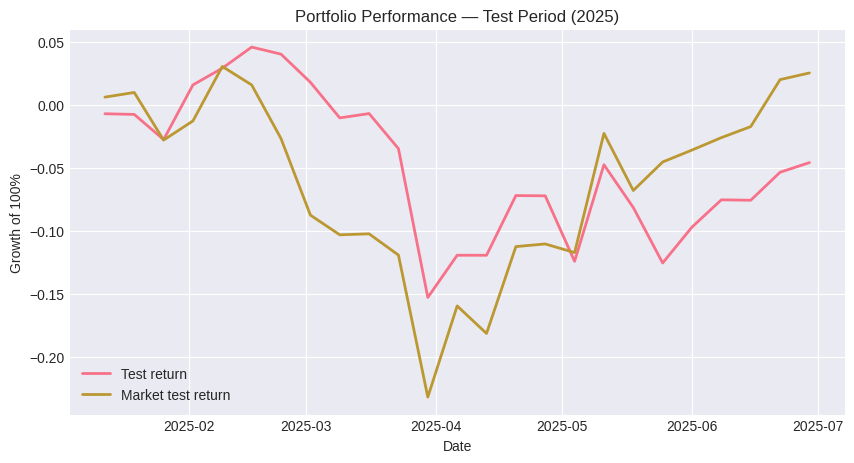

In [35]:
plt.figure(figsize=(10,5))

plt.plot(cum_test_BL.index, cum_test_BL, label="Test return", linewidth=2)
plt.plot(cum_test_market.index, cum_test_market, label="Market test return", linewidth=2)

plt.title("Portfolio Performance — Test Period (2025)")
plt.xlabel("Date")
plt.ylabel("Growth of 100%")
plt.legend()
plt.grid(True)

plt.show()

### Step 8

In [36]:
def estimate_inputs(returns, r_f=0.03/52):

    mu = returns.mean().values          # mean return
    Sigma = returns.cov().values        # cov matrix

    excess_mu = mu - r_f

    return mu, excess_mu, Sigma

In [37]:
def kelly_weights(mu, excess_mu, Sigma, r_f=0.03/52):

    inv_Sigma = np.linalg.inv(Sigma)

    f_star = (1 + r_f) * (inv_Sigma @ excess_mu)

    return f_star

In [38]:
def scale_weights(f_star, scale=1.0):
    return scale * f_star

In [39]:
def portfolio_returns(returns, weights):
    """
    returns: DataFrame (T x N)
    weights: (N,)
    """
    return returns.values @ weights

In [40]:
def performance_metrics(port_ret, r_f=0.03/52):

    mean_ret = np.mean(port_ret)
    vol = np.std(port_ret)
    sharpe = (mean_ret - r_f) / vol if vol != 0 else 0

    wealth = np.cumprod(1 + port_ret)
    max_dd = np.max(np.maximum.accumulate(wealth) - wealth) / np.maximum.accumulate(wealth).max()

    cagr = wealth[-1]**(1/len(port_ret)) - 1

    return {
        "Mean": mean_ret,
        "Volatility": vol,
        "Sharpe": sharpe,
        "Max Drawdown": max_dd,
        "Final Wealth": wealth[-1]
    }

In [41]:
def run_kelly_strategies(returns_train, returns_test, r_f=0.03/52):

    mu, excess_mu, Sigma = estimate_inputs(returns_train, r_f)

    f_kelly = kelly_weights(mu, excess_mu, Sigma, r_f)
    f_half = scale_weights(f_kelly, 0.5)
    f_double = scale_weights(f_kelly, 2.0)

    strategies = {
        "Kelly": f_kelly,
        "Half Kelly": f_half,
        "Double Kelly": f_double
    }

    results = {}

    for name, w in strategies.items():

        train_ret = portfolio_returns(returns_train, w)
        test_ret = portfolio_returns(returns_test, w)

        results[name] = {
            "Train Metrics": performance_metrics(train_ret, r_f),
            "Test Metrics": performance_metrics(test_ret, r_f),
            "Train Wealth": np.cumprod(1 + train_ret),
            "Test Wealth": np.cumprod(1 + test_ret)
        }

    return results, strategies

In [42]:
def plot_wealth(results, dataset="Train"):

    plt.figure(figsize=(10,6))
    for name in results:
        wealth = results[name][f"{dataset} Wealth"]
        plt.plot(wealth, label=name)

    plt.legend()
    plt.title(f"{dataset} Wealth Comparison")
    plt.xlabel("Time")
    plt.ylabel("Wealth")
    plt.show()

In [43]:
def results_table(results, dataset="Test"):

    rows = []

    for name in results:
        metrics = results[name][f"{dataset} Metrics"]
        metrics["Strategy"] = name
        rows.append(metrics)

    df = pd.DataFrame(rows).set_index("Strategy")
    return df

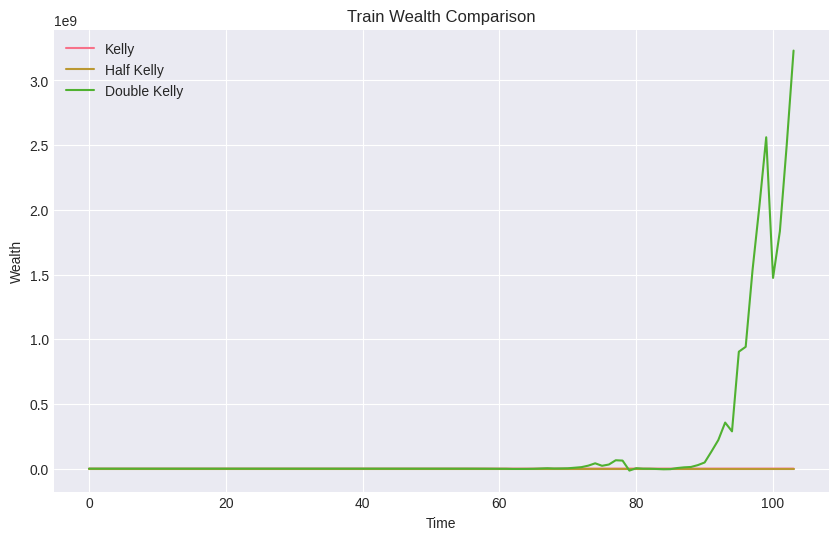

TRAIN RESULTS
                  Mean  Volatility    Sharpe  Max Drawdown  Final Wealth
Strategy                                                                
Kelly         0.207354    0.446257  0.463359      1.529779 -9.351861e+03
Half Kelly    0.103677    0.223128  0.462067      0.235442  2.801294e+03
Double Kelly  0.414708    0.892514  0.464006      0.336486  3.230889e+09


In [44]:
results, weights = run_kelly_strategies(
    train_return,
    test_return,
    r_f= 0.03/52
)

# Plots
plot_wealth(results, "Train")

# Tables
train_table = results_table(results, "Train")

print("TRAIN RESULTS")
print(train_table)

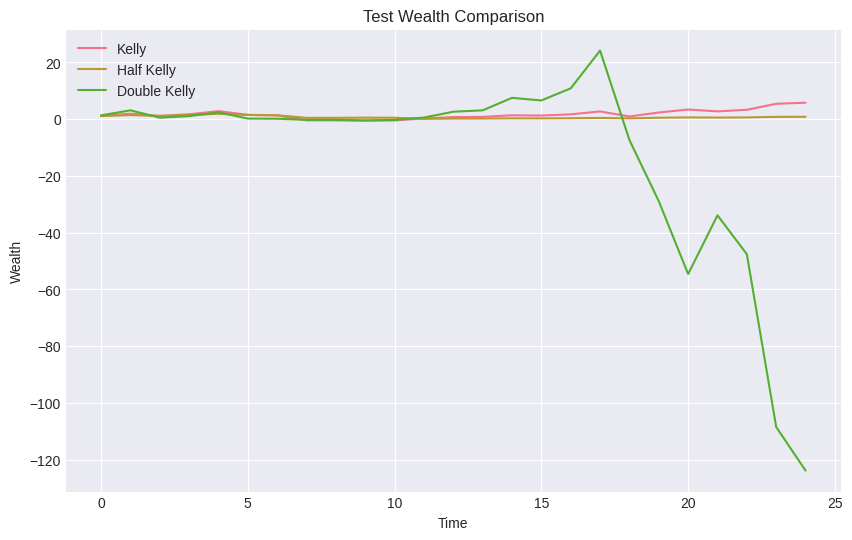


TEST RESULTS
                  Mean  Volatility    Sharpe  Max Drawdown  Final Wealth
Strategy                                                                
Kelly         0.149205    0.718268  0.206926      0.582596      5.803853
Half Kelly    0.074603    0.359134  0.206123      0.943185      0.837262
Double Kelly  0.298410    1.436536  0.207328      6.124343   -123.856710


In [45]:
# plot test
plot_wealth(results, "Test")

test_table = results_table(results, "Test")

print("\nTEST RESULTS")
print(test_table)